In [224]:
# importing required packages
# data operation libraries

import numpy as np
import pandas as pd

# visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns
from mpl_toolkits.mplot3d import axes3d

# For regression
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import scale
import sklearn.linear_model as skl_lm
from sklearn.metrics import mean_squared_error, r2_score
import statsmodels.api as sm
import statsmodels.formula.api as smf

%matplotlib inline
# plt.style.use('seaborn-white')

In [400]:
day_data = pd.read_csv('G:/Python/AIML-TimesPro/Projects/Module 2/day.csv')


In [399]:
day_data.head()


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


# Task 1: Simple Linear Regression

### (a) Load the dataset and create a scatter plot of the ’temp’ variable against the ’cnt’ (rental count) variable.

<Axes: xlabel='temp', ylabel='cnt'>

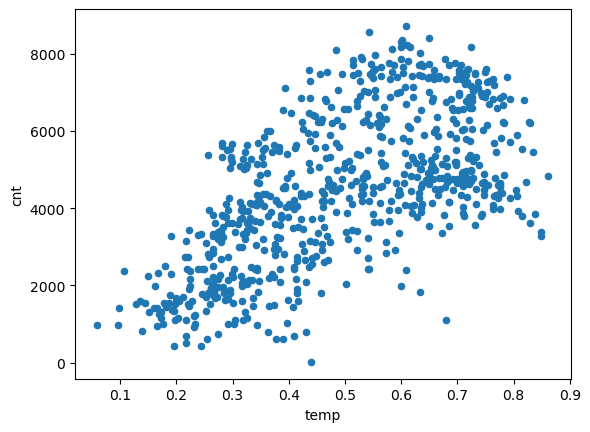

In [466]:
# Visualise the relationship between the features and the response using scatterplots
day_data_task1 = day_data[['temp','cnt']]
day_data_task1.plot(x='temp',y='cnt',kind='scatter')

In [402]:
day_data_task1.dtypes

temp    float64
cnt       int64
dtype: object

### Profiling

In [467]:
# Create Data audit Report for continuous variables
def continuous_var_summary(x):
    return pd.Series([x.count(), x.isnull().sum(), x.sum(), x.mean(), x.median(),  
                      x.std(), x.var(), x.min(), x.quantile(0.01), x.quantile(0.05),
                          x.quantile(0.10),x.quantile(0.25),x.quantile(0.50),x.quantile(0.75), 
                              x.quantile(0.90),x.quantile(0.95), x.quantile(0.99),x.max()], 
                  index = ['N', 'NMISS', 'SUM', 'MEAN','MEDIAN', 'STD', 'VAR', 'MIN', 'P1', 
                               'P5' ,'P10' ,'P25' ,'P50' ,'P75' ,'P90' ,'P95' ,'P99' ,'MAX'])


In [468]:
# seperate categorical and continuous variables
day_data_task1_conti_vars = day_data_task1.loc[:, (day_data_task1.dtypes == 'float64') | (day_data_task1.dtypes == 'int64')]
day_data_task1_conti_vars.apply(continuous_var_summary).T.round(2)

,N,NMISS,SUM,MEAN,MEDIAN,STD,VAR,MIN,P1,P5,P10,P25,P50,P75,P90,P95,P99,MAX
temp,731.0,0.0,362.13,0.50,0.5,0.18,0.03,0.06,0.15,0.21,0.26,0.34,0.5,0.66,0.73,0.77,0.83,0.86
cnt,731.0,0.0,3292679.00,4504.35,4548.0,1937.21,3752788.21,22.00,689.60,1331.00,1746.00,3152.00,4548.0,5956.00,7290.00,7576.00,8163.70,8714.00


## Outlier Treatment

In [469]:
# No outliers as such 

### Assumptions check

### Assumption 1 - Linearity

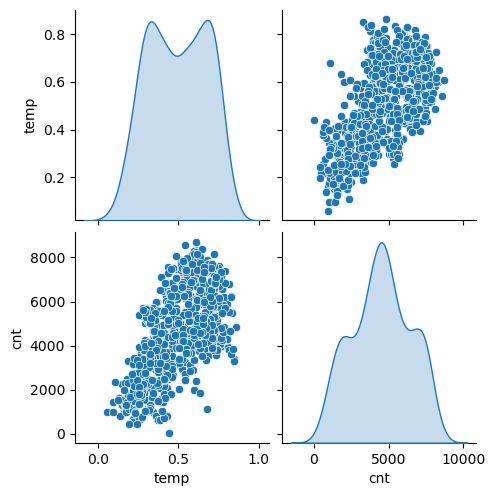

In [470]:
# Distribution of variables
sns.pairplot(day_data_task1_conti_vars, diag_kind='kde')

plt.show()
# this distribution is normally distributed

# Notes:
#-----------------------------------------------------
# 1. if we get skewed data, then we have to transform the data and there are multiple methods to go about it
# 2. most commonly used and which works on most of the data is log transformation

### Assumption 2 - Co-relation

In [471]:
# Linearity: correlation matrix (ranges from 1 to -1)
corrm = day_data_task1_conti_vars.corr()
corrm

,temp,cnt
temp,1.000000,0.627494
cnt,0.627494,1.000000


In [472]:
# Train Test Split: We will split the data into training and testing datasets. The training dataset will be used to train the model, 
# and the testing dataset will be used to evaluate the model's performance.

feature_columns = day_data_task1_conti_vars.columns.difference(['cnt'])  # Exclude the target variable 'cnt' from the feature columns
feature_columns

# method 1: divide the data into training and testing
train, test = train_test_split(day_data_task1_conti_vars, test_size = 0.2, random_state = 12345)

# method 2: divide the data into training and testing and separate out Y and X variables
# this will be used in sklearn related functions
X_train, X_test, y_train, y_test = train_test_split(day_data_task1_conti_vars[feature_columns], 
                                            day_data_task1_conti_vars['cnt'], test_size = 0.2, random_state = 12345)

print("day_data_task1_conti_vars.shape:", day_data_task1_conti_vars.shape)
print("train.shape:", train.shape)
print("test.shape:", test.shape)
print("X_train.shape:", X_train.shape)
print("y_train.shape:", y_train.shape)
print("X_test.shape:", X_test.shape)
print("y_test.shape:", y_test.shape)


day_data_task1_conti_vars.shape: (731, 2)
train.shape: (584, 2)
test.shape: (147, 2)
X_train.shape: (584, 1)
y_train.shape: (584,)
X_test.shape: (147, 1)
y_test.shape: (147,)


### (b) Fit a simple linear regression model using the ’temp’ variable as the predictor.

In [473]:
# import LinearRegression from sklearn
from sklearn.linear_model import LinearRegression

# Representing LinearRegression as lr(Creating LinearRegression Object)
linreg_model_t1 = LinearRegression()

# Fit the model using lr.fit()
linreg_model_t1.fit(X_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [474]:
# Running this model on Training and calculating metrics
from sklearn.metrics import mean_squared_error, r2_score

train['pred_cnt'] = linreg_model_t1.predict(X_train)
mse_train = mean_squared_error(y_train, train.pred_cnt)
r_squared_train = r2_score(y_train, train.pred_cnt)

print('R2 Sq:' ,r_squared_train )
print('Mean Squared error:',  mse_train)

R2 Sq: 0.3840095829303418
Mean Squared error: 2317693.478560771


In [475]:
train.head(20)

,temp,cnt,pred_cnt
147,0.655833,4758,5582.889941
416,0.287826,3777,3136.656707
706,0.320833,5008,3356.062372
471,0.664167,6370,5638.288093
567,0.595833,4459,5184.055152
662,0.587500,7693,5128.663647
604,0.703333,6917,5898.634148
723,0.231304,920,2760.941042
153,0.620000,5312,5344.699158
543,0.697500,7335,5859.860760


### (c) Plot the regression line on the scatter plot and calculate the R-squared value.

In [476]:
# Running this model on Testing and calculating metrics
test['pred_cnt'] = linreg_model_t1.predict(X_test)
mse_test_slr = mean_squared_error(y_test, test.pred_cnt)
r_squared_test_slr = r2_score(y_test, test.pred_cnt)

print('R2 Sq:' ,r_squared_test_slr )
print('Mean Squared error:',  mse_test_slr)

R2 Sq: 0.4324117797562256
Mean Squared error: 2091293.6378359161


Text(0, 0.5, 'Count')

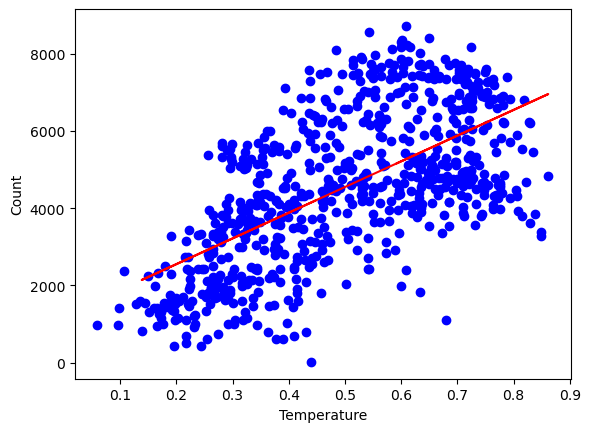

In [477]:
plt.scatter(day_data_task1_conti_vars['temp'],day_data_task1_conti_vars['cnt'],color='blue')
plt.plot(X_test,test['pred_cnt'],color='red')
plt.xlabel('Temperature')
plt.ylabel('Count')

# Task 2: Multiple Linear Regression - Extend the simple linear regression model by including additional features (’atemp’,’hum’, and ’windspeed ’)
#### (a) Train a multiple linear regression model on the dataset.

In [478]:
day_data_task2 = day_data[['temp','atemp','hum','windspeed','cnt']]

In [479]:
day_data_task2.dtypes

temp         float64
atemp        float64
hum          float64
windspeed    float64
cnt            int64
dtype: object

### Profiling

In [480]:
# seperate categorical and continuous variables
day_data_task2_conti_vars = day_data_task2.loc[:, (day_data_task2.dtypes == 'float64') | (day_data_task2.dtypes == 'int64')]
day_data_task2_conti_vars.apply(continuous_var_summary).T.round(2)

,N,NMISS,SUM,MEAN,MEDIAN,STD,VAR,MIN,P1,P5,P10,P25,P50,P75,P90,P95,P99,MAX
temp,731.0,0.0,362.13,0.50,0.50,0.18,0.03,0.06,0.15,0.21,0.26,0.34,0.50,0.66,0.73,0.77,0.83,0.86
atemp,731.0,0.0,346.75,0.47,0.49,0.16,0.03,0.08,0.15,0.22,0.26,0.34,0.49,0.61,0.68,0.71,0.78,0.84
hum,731.0,0.0,458.99,0.63,0.63,0.14,0.02,0.00,0.31,0.41,0.45,0.52,0.63,0.73,0.82,0.87,0.93,0.97
windspeed,731.0,0.0,139.25,0.19,0.18,0.08,0.01,0.02,0.05,0.08,0.10,0.13,0.18,0.23,0.30,0.34,0.41,0.51
cnt,731.0,0.0,3292679.00,4504.35,4548.00,1937.21,3752788.21,22.00,689.60,1331.00,1746.00,3152.00,4548.00,5956.00,7290.00,7576.00,8163.70,8714.00


## Outlier Treatment

In [481]:
# No outliers as such

### Assumptions check

### Assumption 1 - Linearity

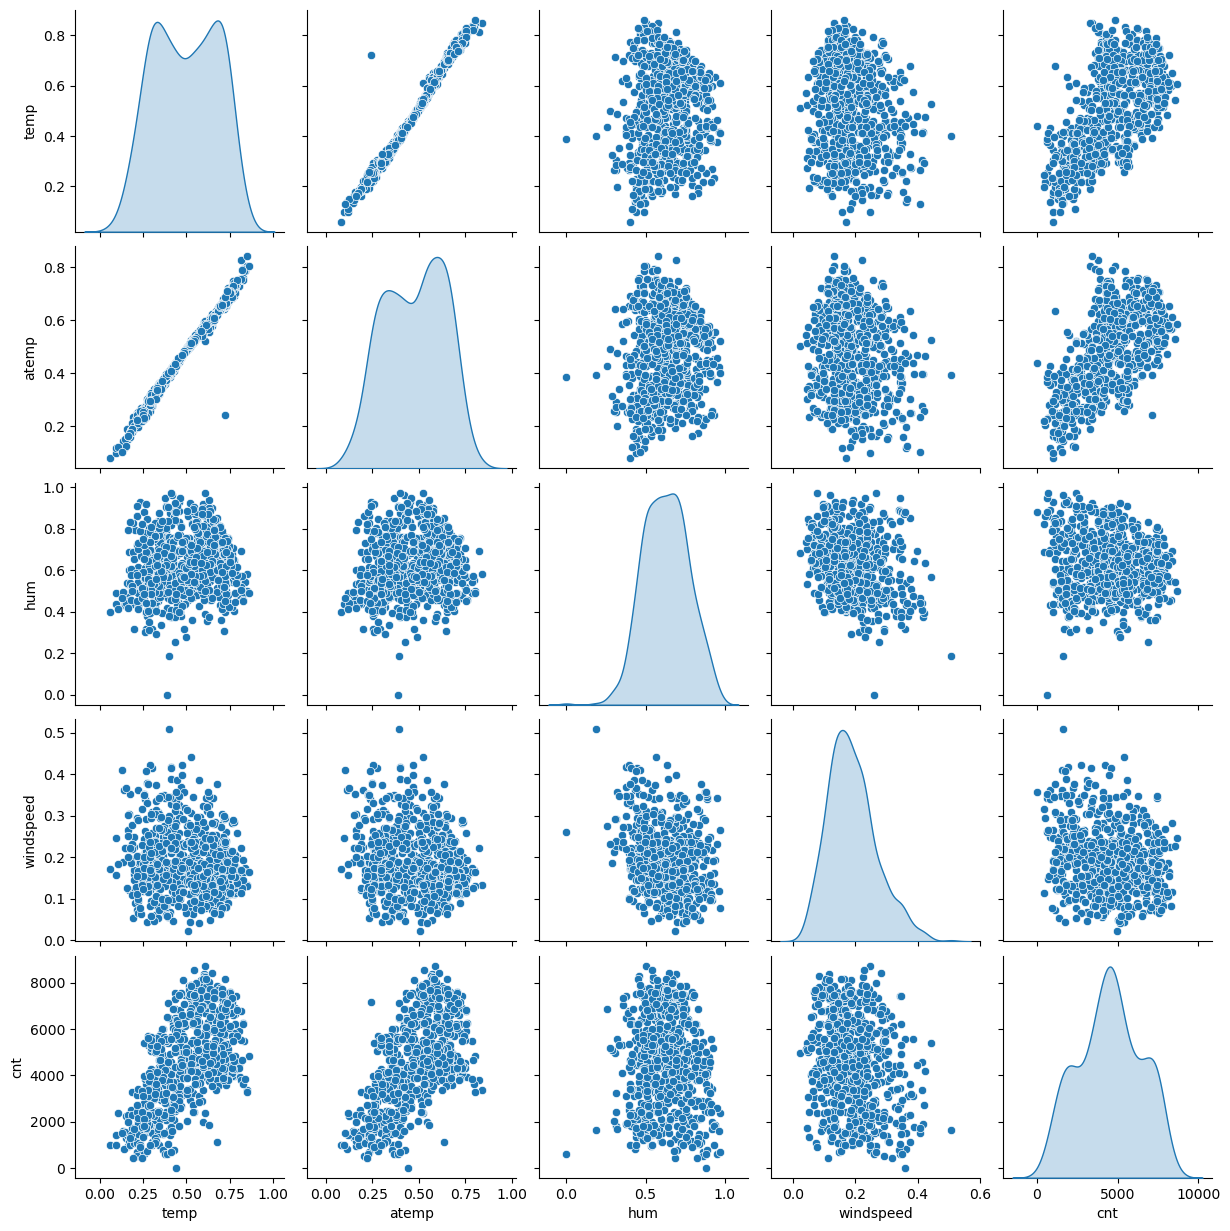

In [482]:
# Visualise the relationship between the features and the response using scatterplots
import seaborn as sns

## Check for linearity. We can also draw the pairplot for checking the relationship
sns.pairplot(day_data_task2_conti_vars, diag_kind='kde')

### Assumption 2 - Co-relation

In [484]:
# Linearity: correlation matrix (ranges from 1 to -1)
corrm = day_data_task2.corr()
corrm

,temp,atemp,hum,windspeed,cnt
temp,1.000000,0.991702,0.126963,-0.157944,0.627494
atemp,0.991702,1.000000,0.139988,-0.183643,0.631066
hum,0.126963,0.139988,1.000000,-0.248489,-0.100659
windspeed,-0.157944,-0.183643,-0.248489,1.000000,-0.234545
cnt,0.627494,0.631066,-0.100659,-0.234545,1.000000


In [485]:
# Train Test Split: We will split the data into training and testing datasets. The training dataset will be used to train the model, 
# and the testing dataset will be used to evaluate the model's performance.

feature_columns = day_data_task2.columns.difference(['cnt'])
feature_columns

# method 1: divide the data into training and testing
train, test = train_test_split(day_data_task2, test_size = 0.2, random_state = 12345)

# method 2: divide the data into training and testing and separate out Y and X variables
# this will be used in sklearn related functions
X_train, X_test, y_train, y_test = train_test_split(day_data_task2[feature_columns], 
                                            day_data_task2['cnt'], test_size = 0.2, random_state = 12345)

print("day_data_task2.shape:", day_data_task2.shape)
print("train.shape:", train.shape)
print("test.shape:", test.shape)
print("X_train.shape:", X_train.shape)
print("y_train.shape:", y_train.shape)
print("X_test.shape:", X_test.shape)
print("y_test.shape:", y_test.shape)


day_data_task2.shape: (731, 5)
train.shape: (584, 5)
test.shape: (147, 5)
X_train.shape: (584, 4)
y_train.shape: (584,)
X_test.shape: (147, 4)
y_test.shape: (147,)


### (b) Predict the number of bike rentals using the trained model.

In [486]:
# import LinearRegression from sklearn
from sklearn.linear_model import LinearRegression

# Representing LinearRegression as lr(Creating LinearRegression Object)
linreg_model_t2 = LinearRegression()

# Fit the model using lr.fit()
linreg_model_t2.fit(X_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [487]:
# Running this model on Training and calculating metrics
from sklearn.metrics import mean_squared_error, r2_score

train['pred_cnt'] = linreg_model_t2.predict(X_train)
mse_train = mean_squared_error(y_train, train.pred_cnt)
r_squared_train = r2_score(y_train, train.pred_cnt)

print('R2 Sq:' ,r_squared_train )
print('Mean Squared error:',  mse_train)

R2 Sq: 0.46697219380287347
Mean Squared error: 2005542.6774194967


In [488]:
train.head()

,temp,atemp,hum,windspeed,cnt,pred_cnt
147,0.655833,0.612379,0.729583,0.230092,4758,5046.107347
416,0.287826,0.295113,0.594348,0.205717,3777,3189.238863
706,0.320833,0.321958,0.764167,0.130600,5008,3107.340520
471,0.664167,0.614925,0.561667,0.284829,6370,5452.533817
567,0.595833,0.549912,0.865417,0.213300,4459,4169.056196


### (c) Calculate the Mean Squared Error (MSE) and plot the residuals.

In [489]:
# Running this model on Testing and calculating metrics
test['pred_cnt'] = linreg_model_t2.predict(X_test)
mse_test_mlr = mean_squared_error(y_test, test.pred_cnt)
r_squared_test_mlr = r2_score(y_test, test.pred_cnt)

print('R2 Sq:' ,r_squared_test_mlr )
print('Mean Squared error:',  mse_test_mlr)

R2 Sq: 0.44256416709179613
Mean Squared error: 2053886.901250358


Text(0, 0.5, 'Frequency')

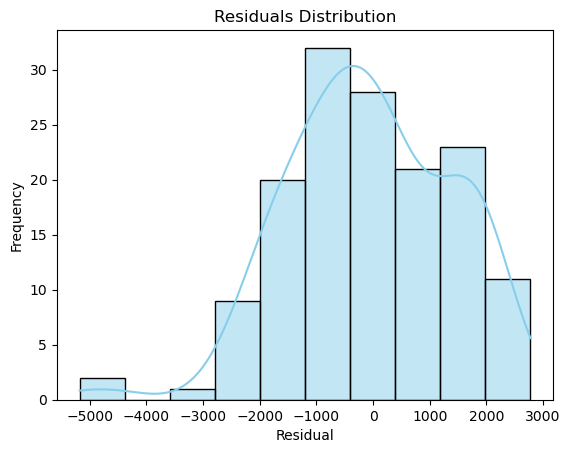

In [490]:
residuals = test['cnt'] - test['pred_cnt']
sns.histplot(residuals, kde=True, color='skyblue')
plt.title('Residuals Distribution')
plt.xlabel('Residual')
plt.ylabel('Frequency')
# plt.show()

In [491]:
# # Assumption 2: mean of residuals/errors is zero
# Assumption check failed
print(residuals.mean())

-70.52146795547117


In [492]:
# Assumption 3: residuals/errors of the model should not be correlated with dependant (Y) variable
# We can see that residual error is highly co-related (0.85) meaning model has heteroscadicity
corr_coeff = residuals.corr(test['cnt'], method='pearson')
print(corr_coeff)

0.6766896971705596


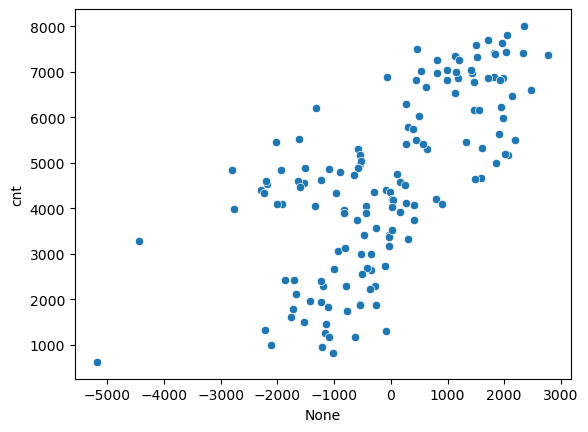

In [493]:
# Assumption 4: homoscedasticity of residuals/errors
import seaborn as sns
sns.scatterplot(x=residuals,y=test.cnt)
plt.show()
# We can see that as the value of Y is increasing the residual error is also increasing , 
# This is Heteroscadicity

# Task 3: Non Linear Regression - Implement a nonlinear regression model using polynomial features.

### (a) Create a polynomial feature (’temp2’) by squaring the ’temp’ variable..

In [494]:
day_data_task3 = day_data[['temp','cnt']].copy()
day_data_task3['temp2'] = day_data_task3['temp'] ** 2
day_data_task3.head()

,temp,cnt,temp2
0,0.344167,985,0.118451
1,0.363478,801,0.132116
2,0.196364,1349,0.038559
3,0.200000,1562,0.040000
4,0.226957,1600,0.051509


In [495]:
day_data_task3.dtypes

temp     float64
cnt        int64
temp2    float64
dtype: object

### Profiling

In [496]:
# seperate categorical and continuous variables
day_data_task3_conti_vars = day_data_task3.loc[:, (day_data_task3.dtypes == 'float64') | (day_data_task3.dtypes == 'int64')]
day_data_task3_conti_vars.apply(continuous_var_summary).T.round(2)

,N,NMISS,SUM,MEAN,MEDIAN,STD,VAR,MIN,P1,P5,P10,P25,P50,P75,P90,P95,P99,MAX
temp,731.0,0.0,362.13,0.50,0.50,0.18,0.03,0.06,0.15,0.21,0.26,0.34,0.50,0.66,0.73,0.77,0.83,0.86
cnt,731.0,0.0,3292679.00,4504.35,4548.00,1937.21,3752788.21,22.00,689.60,1331.00,1746.00,3152.00,4548.00,5956.00,7290.00,7576.00,8163.70,8714.00
temp2,731.0,0.0,203.85,0.28,0.25,0.18,0.03,0.00,0.02,0.05,0.07,0.11,0.25,0.43,0.54,0.59,0.68,0.74


## Outlier Treatment

In [454]:
# No outliers as such

### Assumptions check

### Assumption 1 - Linearity

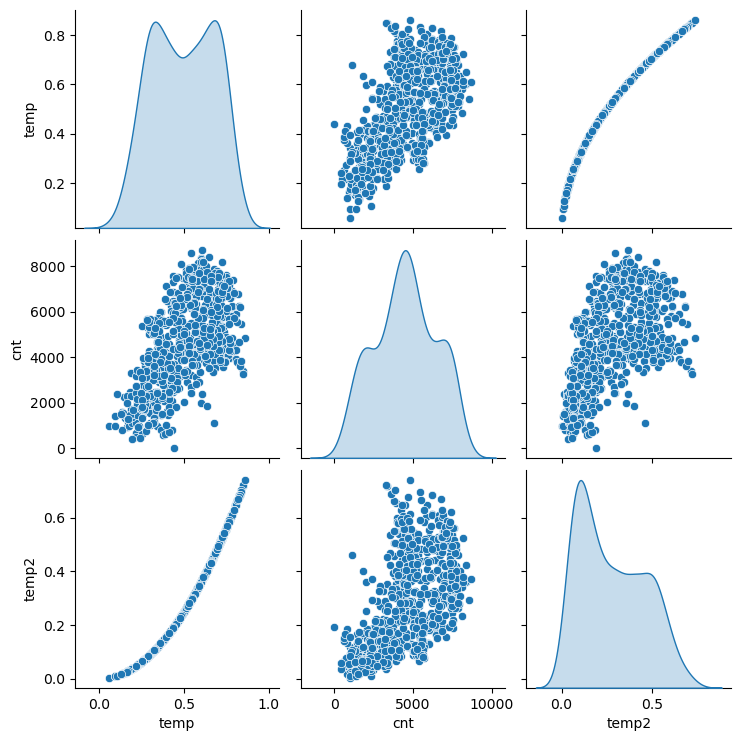

In [497]:
# Visualise the relationship between the features and the response using scatterplots
import seaborn as sns

## Check for linearity. We can also draw the pairplot for checking the relationship
sns.pairplot(day_data_task3, diag_kind='kde')

### Assumption 2 - Co-relation

In [498]:
# Linearity: correlation matrix (ranges from 1 to -1)
corrm = day_data_task3.corr()
corrm

,temp,cnt,temp2
temp,1.000000,0.627494,0.985077
cnt,0.627494,1.000000,0.576172
temp2,0.985077,0.576172,1.000000


In [499]:
# Train Test Split: We will split the data into training and testing datasets. The training dataset will be used to train the model, 
# and the testing dataset will be used to evaluate the model's performance.

feature_columns = day_data_task3.columns.difference(['cnt'])
feature_columns

# method 1: divide the data into training and testing
train, test = train_test_split(day_data_task3, test_size = 0.2, random_state = 12345)

# method 2: divide the data into training and testing and separate out Y and X variables
# this will be used in sklearn related functions
X_train, X_test, y_train, y_test = train_test_split(day_data_task3[feature_columns], 
                                            day_data_task3['cnt'], test_size = 0.2, random_state = 12345)

print("day_data_task3.shape:", day_data_task3.shape)
print("train.shape:", train.shape)
print("test.shape:", test.shape)
print("X_train.shape:", X_train.shape)
print("y_train.shape:", y_train.shape)
print("X_test.shape:", X_test.shape)
print("y_test.shape:", y_test.shape)


day_data_task3.shape: (731, 3)
train.shape: (584, 3)
test.shape: (147, 3)
X_train.shape: (584, 2)
y_train.shape: (584,)
X_test.shape: (147, 2)
y_test.shape: (147,)


### (b) Predict the number of bike rentals using the trained model.

In [500]:
# import LinearRegression from sklearn
from sklearn.linear_model import LinearRegression

# Representing LinearRegression as lr(Creating LinearRegression Object)
linreg_model_t3 = LinearRegression()

# Fit the model using lr.fit()
linreg_model_t3.fit(X_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [501]:
# Running this model on Training and calculating metrics
from sklearn.metrics import mean_squared_error, r2_score

train['pred_cnt'] = linreg_model_t3.predict(X_train)
mse_train = mean_squared_error(y_train, train.pred_cnt)
r_squared_train = r2_score(y_train, train.pred_cnt)

print('R2 Sq:' ,r_squared_train )
print('Mean Squared error:',  mse_train)

R2 Sq: 0.4357402769607742
Mean Squared error: 2123054.261986404


In [502]:
train.head()

,temp,cnt,temp2,pred_cnt
147,0.655833,4758,0.430117,5639.023016
416,0.287826,3777,0.082844,3042.446671
706,0.320833,5008,0.102934,3433.038598
471,0.664167,6370,0.441118,5653.093625
567,0.595833,4459,0.355017,5479.247239


### (c) Calculate the Mean Squared Error (MSE) and plot the residuals.

In [503]:
# Running this model on Testing and calculating metrics
test['pred_cnt'] = linreg_model_t3.predict(X_test)
mse_test_plr = mean_squared_error(y_test, test.pred_cnt)
r_squared_test_plr = r2_score(y_test, test.pred_cnt)

print('R2 Sq:' ,r_squared_test_plr )
print('Mean Squared error:',  mse_test_plr)

R2 Sq: 0.5219090705851548
Mean Squared error: 1761538.5297512128


Text(0, 0.5, 'Frequency')

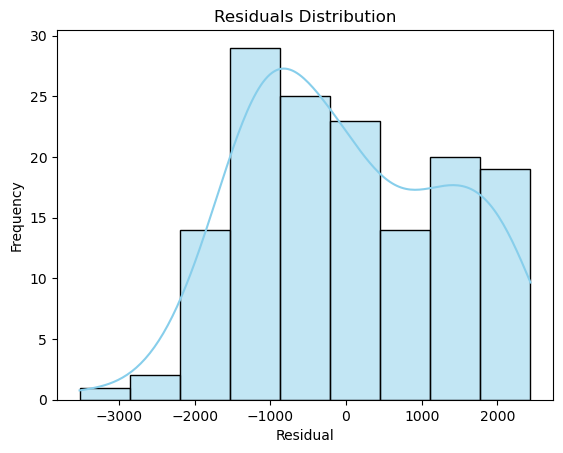

In [504]:
residuals = test['cnt'] - test['pred_cnt']
sns.histplot(residuals, kde=True, color='skyblue')
plt.title('Residuals Distribution')
plt.xlabel('Residual')
plt.ylabel('Frequency')
# plt.show()

In [505]:
# # Assumption 2: mean of residuals/errors is zero
# Assumption check failed
print(residuals.mean())

-1.5597052926500665


In [506]:
# Assumption 3: residuals/errors of the model should not be correlated with dependant (Y) variable
# We can see that residual error is highly co-related (0.85) meaning model has heteroscadicity
corr_coeff = residuals.corr(test['cnt'], method='pearson')
print(corr_coeff)

0.7621313488297441


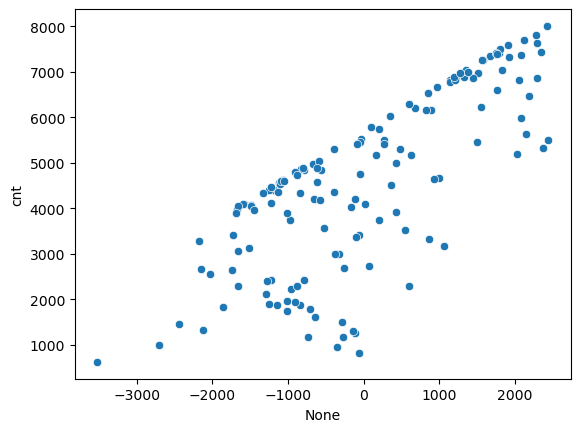

In [508]:
# Assumption 4: homoscedasticity of residuals/errors
import seaborn as sns
sns.scatterplot(x=residuals,y=test.cnt)
plt.show()
# We can see that as the value of Y is increasing the residual error is also increasing , 
# This is Heteroscadicity

# Conclusion

In [559]:
from IPython.display import display
from IPython.display import display, Markdown

summary_df = pd.DataFrame({
    'Model': ['Simple Linear Regression', 'Multiple Linear Regression', 'Polynomial Regression'],
    'R2 Test': [r_squared_test_slr, r_squared_test_mlr, r_squared_test_plr],
    'MSE Test': [mse_test_slr, mse_test_mlr, mse_test_plr]
})

summary_df_display = summary_df.copy()
summary_df_display['R2 Test'] = summary_df_display['R2 Test'].map('{:.4f}'.format)
summary_df_display['MSE Test'] = summary_df_display['MSE Test'].map('{:,.2f}'.format)

display(summary_df_display)

best_by_r2 = summary_df.loc[summary_df['R2 Test'].idxmax(), 'Model']
best_by_mse = summary_df.loc[summary_df['MSE Test'].idxmin(), 'Model']

print("=" * 100)

display(Markdown(f"**Best model by R2:** **{best_by_r2}**"))
display(Markdown(f"**Best model by MSE:** **{best_by_mse}**"))


,Model,R2 Test,MSE Test
0,Simple Linear Regression,0.4324,"2,091,293.64"
1,Multiple Linear Regression,0.4426,"2,053,886.90"
2,Polynomial Regression,0.5219,"1,761,538.53"


**Best model by R2:** **Polynomial Regression**

**Best model by MSE:** **Polynomial Regression**